# Кто снизил активность по картам и почему: группы для кампании возврата

*Банк «Меридиан», данные синтетические. База: 2024 год, оценка: январь-июнь 2025. Автор: Демидов Дмиитрий. Расчёты: 01_analysis.ipynb.*

## 1. Главное

1. **Активность по картам упала на 10,2%**, а не на 17,2%, как выглядит при сравнении со средним месяцем 2024 года создаётся сезонность.
2. **Предлагаем 5 групп: 1 289 клиентов с согласием при лимите 2 000** (G1 364, G2 403, G3 202, G4 160, G5 160). Вместе они дают 58,1% недобора операций банка за полугодие.
3. **За счёт чего упало.** У G1, G2 и G5 клиенты стали реже платить во всех каналах и категориях поровну; у G3 и особенно G4 заметно просели кафе и рестораны (в G4 индекс по кафе 0,13 при остальных тратах на уровне прошлого года).
4. **Оговорки.** Данные не объясняют мотивов клиентов; метрика не видит снижения среднего чека и ухода в другие банки; группы отобраны по уже случившемуся падению, поэтому вернуть удастся меньше, чем недобрано.

## 2. Контекст

Департамент розничных продуктов заметил, что клиенты реже пользуются картами, и готовит кампанию возврата активности. Условия: не более 2 000 клиентов; от 3 до 5 групп не меньше 150 человек (под каждую своя коммуникация); каждая группа описана правилом по признакам клиента и характером падения, чтобы правило можно было применить к новой выгрузке; по каждой нужна причина падения; связываться можно только с клиентами, давшими согласие.

## 3. Данные и ограничения

**Данные.** Период 2024-01-01 - 2025-06-30: база 2024 (12 месяцев), оценка январь-июнь 2025 (6 месяцев), поэтому всё считаем в расчёте на месяц и сравниваем одинаковые месяцы. Исходно 5 639 клиентов в справочнике, 623 808 операций и ещё 361 клиентов, которые есть только в операциях. После очистки: 5 625 клиентов и 592 149 операций, из них 573 126 успешных. **Исключено:** 1 500 повторов операций (технические дубли выгрузки), 92 операции вне периода (до января 2024 и после даты выгрузки), 361 клиентов вне справочника действующих (28 921 операции; они исчезают из операций к апрелю 2025, вероятно, ушли из банка; сегмента и согласия для них нет) и 14 клиентов с двумя версиями города или сегмента (1 146 операция). **Чего в данных нет:** причин и мотивов клиентов (опросы, обращения), операций в других банках и наличных, остатков, кредитов и других продуктов, курса для EUR/USD (0,4% операций), второго базового года для проверки сезонности. Канал оплаты не соответствует описанию (онлайн-банк и СБП встречаются на АЗС и в кафе), поэтому используем его только для динамики.

**Метрика активности.** Активность клиента это число успешных операций в месяц (все каналы и валюты; отклонённые операции и возвраты не считаем). Для клиента считаем *индекс активности*: факт января-июня 2025 к ожидаемому при неизменном поведении; ожидаемое это среднее число операций в месяц в 2024 году, умноженное на сезонные коэффициенты банка (в 2024 году декабрь был 1,29 среднего месяца, январь низким). Индекс 1 значит «как раньше», 0,5 вдвое меньше. Падение измеряем у клиентов с базой не менее 2 операций в месяц (4 709 клиентов). **Метрика не видит:** снижение среднего чека при том же числе операций, уход к другим банкам или на наличные, падение у клиентов с очень малой базой и у тех, у кого в 2024 году операций не было (407 клиентов).

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook", font_scale=0.85)
plt.rcParams.update({"figure.dpi": 130, "axes.titlesize": 10, "axes.titleweight": "bold", "axes.labelsize": 9,
                     "legend.fontsize": 8, "legend.title_fontsize": 8})
COLORS = {"Массовый, без приложения": "#C44E52", "Массовый, с приложением": "#DD8452",
          "Зарплатный": "#4C72B0", "Премиальный и Private": "#55A868"}

def ru(s):
    return re.sub(r"(?<=\d)\.(?=\d)", ",", str(s))

def read_table(name):

    p = Path(f"{name}.parquet")
    return pd.read_parquet(p) if p.exists() else pd.read_csv(f"{name}.csv.gz")

clients = read_table("clients_clean")
tx = read_table("tx_clean")
tx["txn_datetime"] = pd.to_datetime(tx["txn_datetime"])
tx["month"] = pd.PeriodIndex(tx["month"], freq="M")
for c in ["birth_date", "registration_date", "card_open_date", "app_last_login"]:
    clients[c] = pd.to_datetime(clients[c])
metrics = pd.read_csv("client_metrics.csv")
campaign = pd.read_csv("campaign_list.csv")
log = pd.read_csv("cleaning_log.csv", keep_default_na=False)
ok = tx[tx.status == "успешно"]

In [2]:
K = {}
def L(field, issue_part):
    r = log[(log.field == field) & log.issue.str.contains(issue_part, regex=False)]
    return r.iloc[0]
def n_of(field, part):
    return int(L(field, part)["n_rows"])
K["n_clients"], K["n_tx"], K["n_ok"] = len(clients), len(tx), len(ok)
by_month = ok.groupby("month").size()
cal = pd.DataFrame({"2024": by_month[by_month.index.year == 2024].values,
                    "2025": list(by_month[by_month.index.year == 2025].values) + [np.nan] * 6}, index=range(1, 13))
h1_24, h1_25 = cal.loc[1:6, "2024"].sum(), cal.loc[1:6, "2025"].sum()
K["naive"] = (h1_25 / 6) / (cal["2024"].sum() / 12) - 1
K["like"] = h1_25 / h1_24 - 1
hist_ids = ok.loc[ok.period == "base", "client_id"].unique()
K["like_hist"] = ok[(ok.period == "eval") & ok.client_id.isin(hist_ids)].shape[0] / h1_24 - 1
K["dec_peak"] = cal.loc[12, "2024"] / cal["2024"].mean()

ch = ok.groupby(["month", "channel"]).size().unstack()
ch_share = ch.div(ch.sum(axis=1), axis=0) * 100
y24, y25 = ch_share.index.year == 2024, ch_share.index.year == 2025
K["tok24"], K["tok25"] = ch_share.loc[y24, "Токен"].mean(), ch_share.loc[y25, "Токен"].mean()
K["car24"], K["car25"] = ch_share.loc[y24, "Карта"].mean(), ch_share.loc[y25, "Карта"].mean()
K["ob_low"] = ch_share["Онлайн-банк"].loc["2025-03":"2025-04"].mean()
K["ob_norm_lo"], K["ob_norm_hi"] = ch_share["Онлайн-банк"].loc[["2025-01", "2025-02", "2025-05", "2025-06"]].min(), ch_share["Онлайн-банк"].loc[["2025-01", "2025-02", "2025-05", "2025-06"]].max()

cl_c = clients.set_index("client_id")
def cohort(seg, app):
    return np.select([(seg == "Массовый") & (app == "Нет"), (seg == "Массовый") & (app == "Да"), seg == "Зарплатный"],
                     ["Массовый, без приложения", "Массовый, с приложением", "Зарплатный"], default="Премиальный и Private")
okc = ok.merge(clients[["client_id", "segment", "has_mobile_app", "city"]], on="client_id")
okc["cohort"] = cohort(okc.segment, okc.has_mobile_app)
okc["mon"], okc["yr"] = okc.month.dt.month, okc.month.dt.year
a24 = okc[okc.yr == 2024].groupby(["cohort", "mon"]).size(); a25 = okc[okc.yr == 2025].groupby(["cohort", "mon"]).size()
coh_ratio = (a25 / a24.reindex(a25.index)).unstack()
K["coh"] = coh_ratio.round(2)

cnt = ok.pivot_table(index="client_id", columns="month", values="txn_id", aggfunc="count", fill_value=0)
m24 = [m for m in cnt.columns if m.year == 2024]
bank24 = cnt[m24].sum()
season = pd.Series((bank24 / bank24.mean()).values, index=range(1, 13))
H1_SEASON = season.loc[1:6].sum()

h1b = okc[(okc.yr == 2024) & (okc.mon <= 6)]; h1e = okc[okc.yr == 2025]
cat_ratio = (h1e.groupby("category").size() / h1b.groupby("category").size()).sort_values()
K["cafe_ratio"], K["cat_ratio_all"] = cat_ratio["Кафе и рестораны"], len(h1e) / len(h1b)
K["cat_other_lo"], K["cat_other_hi"] = cat_ratio.drop("Кафе и рестораны").min(), cat_ratio.drop("Кафе и рестораны").max()

G = metrics[metrics.group.notna() & (metrics.group != "")].copy()
GROUPS = sorted(G.group.unique())
K["n_campaign"] = len(campaign)
metrics["lost"] = metrics.exp_all - metrics.act_all
gross = metrics.lost.clip(lower=0).sum()
K["gross"] = gross
K["measurable"], K["no_hist"] = int(metrics.measurable.sum()), int((metrics.base12 == 0).sum())
K["ai_bank"] = metrics.act_all[metrics.base12 > 0].sum() / metrics.exp_all[metrics.base12 > 0].sum()
K["share_low"] = (metrics.loc[metrics.measurable, "ai"] <= 0.6).mean()
sz = G.groupby("group").size()
loss_share = (G.groupby("group").lost.sum() / gross * 100)
K["cover"] = G.lost.sum() / gross * 100
for g in GROUPS:
    K[g[:2]] = int(sz[g]); K[g[:2] + "_loss"] = loss_share[g]

def idx_table(dim):
    b = ok[ok.period == "base"].pivot_table(index="client_id", columns=dim, values="txn_id", aggfunc="count", fill_value=0)
    e = ok[ok.period == "eval"].pivot_table(index="client_id", columns=dim, values="txn_id", aggfunc="count", fill_value=0)
    b, e = b.reindex(metrics.client_id).fillna(0), e.reindex(metrics.client_id).fillna(0)
    expd = b / 12 * H1_SEASON
    rows = {}
    for g in GROUPS:
        sel = (metrics.group == g).values
        rows[g] = e[sel].sum() / expd[sel].sum()
    return pd.DataFrame(rows).T
idx_ch, idx_cat = idx_table("channel"), idx_table("category")
K["cafe_g4"] = idx_cat.loc[GROUPS[3], "Кафе и рестораны"]

spend = ok[ok.is_rub].pivot_table(index="client_id", columns="period", values="amount", aggfunc="sum")
K["spend_ratio"] = spend["eval"].sum() / (spend["base"].sum() / 12 * H1_SEASON)
K["count_ratio"] = metrics.act_all.sum() / metrics.exp_all.sum()

b_ch = ok[ok.period == "base"].pivot_table(index="client_id", columns="channel", values="txn_id", aggfunc="count", fill_value=0).reindex(metrics.client_id).fillna(0)
e_ch = ok[ok.period == "eval"].pivot_table(index="client_id", columns="channel", values="txn_id", aggfunc="count", fill_value=0).reindex(metrics.client_id).fillna(0)
card_i = (e_ch["Карта"] / (b_ch["Карта"] / 12 * H1_SEASON).replace(0, np.nan)).values
tok_i = (e_ch["Токен"] / (b_ch["Токен"] / 12 * H1_SEASON).replace(0, np.nan)).values
swap = metrics.measurable.values & (metrics.ai.values >= 0.9) & (card_i <= 0.8) & (tok_i >= 1.2)
K["swap"] = int(swap.sum())

K["ops_orph"], K["ops_conf"] = n_of("client_id", "нет в справочнике"), n_of("client_id", "неоднозначными")
K["ops_out"] = n_of("txn_datetime", "вне периода")
K["dup_tx"] = n_of("transactions: все поля", "точные копии") + n_of("transactions.txn_datetime", "тот же txn_id")
K["dup_cl"] = n_of("clients: все поля", "полные дубли")
prof = {}
cnt_m = cnt.reindex(metrics.client_id).fillna(0)
for g in GROUPS:
    sel = (metrics.group == g).values
    base = metrics.base12[sel].sum()
    prof[g] = [cnt_m.loc[sel, pd.Period(f"2025-{m:02d}")].sum() / (base * season.loc[m]) for m in range(1, 7)]
prof = pd.DataFrame(prof, index=range(1, 7))
K["prof"] = prof.round(2)
K["idx_ch"], K["idx_cat"] = idx_ch.round(2), idx_cat.round(2)

## 4. Находки

### 4.1. Падение на 10%, а не на 17%: 41% видимого падения создаёт сезонность

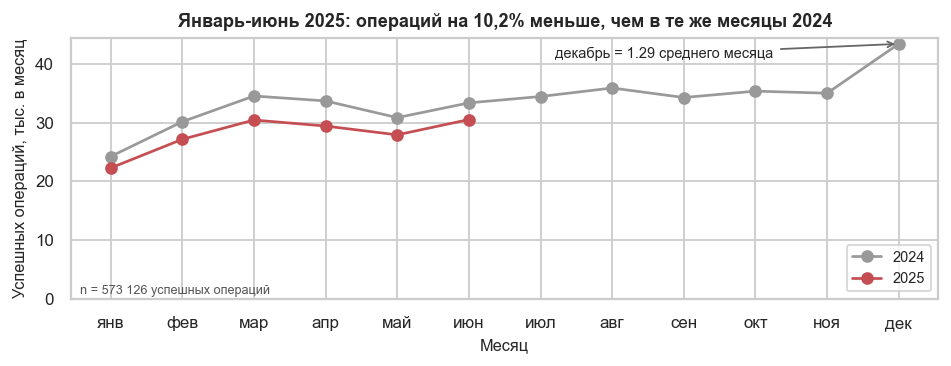

In [3]:
fig, ax = plt.subplots(figsize=(7.2, 2.7), layout="constrained")
ax.plot(cal.index, cal["2024"] / 1000, marker="o", color="#999999", label="2024")
ax.plot(cal.index, cal["2025"] / 1000, marker="o", color="#C44E52", label="2025")
ax.annotate(f"декабрь = {K['dec_peak']:.2f} среднего месяца", xy=(12, cal.loc[12, "2024"] / 1000), xytext=(7.2, 41),
            arrowprops=dict(arrowstyle="->", color="#666"), fontsize=8)
ax.set_xticks(range(1, 13)); ax.set_xticklabels(["янв", "фев", "мар", "апр", "май", "июн", "июл", "авг", "сен", "окт", "ноя", "дек"])
ax.set_ylim(0, None); ax.set_xlabel("Месяц"); ax.set_ylabel("Успешных операций, тыс. в месяц")
ax.set_title(f"Январь-июнь 2025: операций на {abs(K['like']):.1%} меньше, чем в те же месяцы 2024".replace(".", ","))
ax.legend(loc="lower right"); ax.text(0.01, 0.02, f"n = {K['n_ok']:,} успешных операций".replace(",", " "), transform=ax.transAxes, fontsize=7, color="#555")
plt.show()

Если сравнить среднее за месяц 2025 года со средним за месяц 2024 года, падение выглядит как 17,2%. Но в 2024 были высокий декабрь и низкий январь, поэтому правильно сравнивать те же месяцы: январь-июнь 2025 к январю-июню 2024 даёт 10,2%.

### 4.2. Падает массовый сегмент, и без приложения падение углубляется

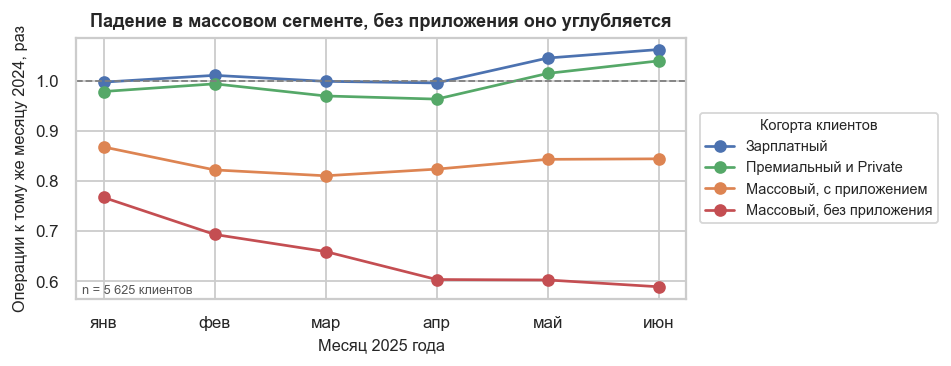

In [4]:
fig, ax = plt.subplots(figsize=(7.2, 2.7), layout="constrained")
for name in ["Зарплатный", "Премиальный и Private", "Массовый, с приложением", "Массовый, без приложения"]:
    ax.plot(coh_ratio.columns, coh_ratio.loc[name], marker="o", color=COLORS[name], label=name)
ax.axhline(1, color="grey", ls="--", lw=1)
ax.set_xticks(range(1, 7)); ax.set_xticklabels(["янв", "фев", "мар", "апр", "май", "июн"])
ax.set_xlabel("Месяц 2025 года"); ax.set_ylabel("Операции к тому же месяцу 2024, раз")
ax.set_title("Падение в массовом сегменте, без приложения оно углубляется")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), title="Когорта клиентов")
ax.text(0.01, 0.02, f"n = {K['n_clients']:,} клиентов".replace(",", " "), transform=ax.transAxes, fontsize=7, color="#555")
plt.show()

У массовых клиентов без приложения операции к тому же месяцу прошлого года снижаются с 0,77 в январе до 0,59 в июне; с приложением падение ступенчатое и дальше ровное (0,81-0,87). Зарплатные и премиальные клиенты вместе с Private остаются на уровне прошлого года.

### 4.3. Карты уходят в токен, а онлайн-банк в марте-апреле временно просел

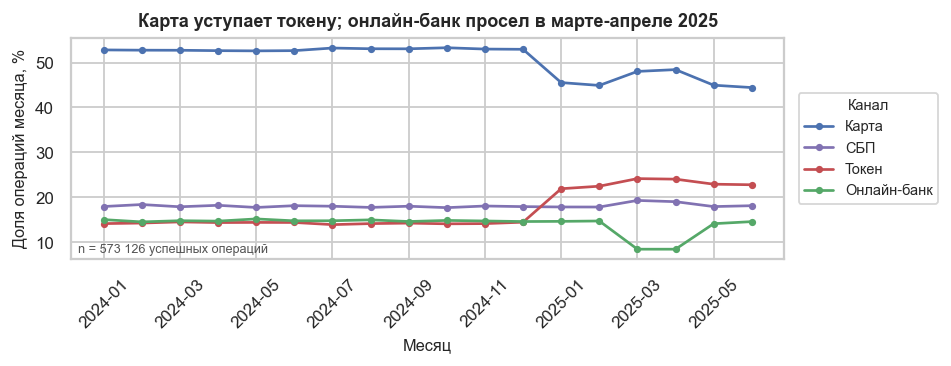

In [5]:
fig, ax = plt.subplots(figsize=(7.2, 2.7), layout="constrained")
x = [str(p) for p in ch_share.index]
for c_, col in [("Карта", "#4C72B0"), ("СБП", "#8172B2"), ("Токен", "#C44E52"), ("Онлайн-банк", "#55A868")]:
    ax.plot(x, ch_share[c_], marker="o", ms=3, color=col, label=c_)
ax.set_xticks(range(0, len(x), 2)); ax.set_xticklabels([x[i] for i in range(0, len(x), 2)], rotation=45)
ax.set_xlabel("Месяц"); ax.set_ylabel("Доля операций месяца, %")
ax.set_title("Карта уступает токену; онлайн-банк просел в марте-апреле 2025")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), title="Канал")
ax.text(0.01, 0.03, f"n = {K['n_ok']:,} успешных операций".replace(",", " "), transform=ax.transAxes, fontsize=7, color="#555")
plt.show()

### 4.4. Кафе и рестораны падают сильнее остальных категорий

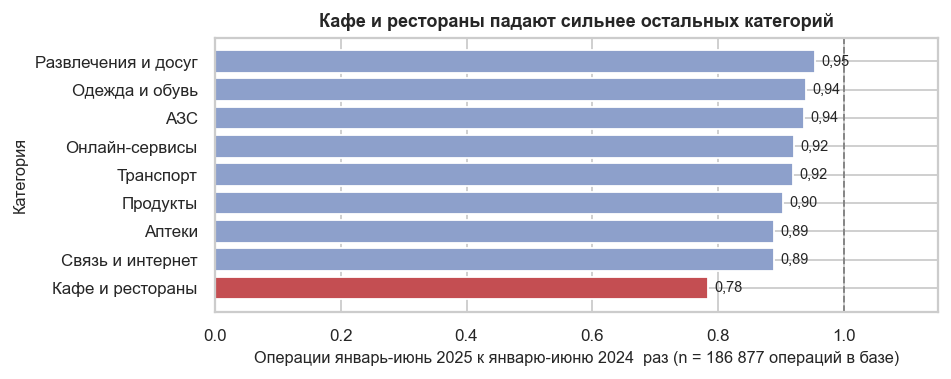

In [6]:
fig, ax = plt.subplots(figsize=(7.2, 2.8), layout="constrained")
cols = ["#C44E52" if c_ == "Кафе и рестораны" else "#8da0cb" for c_ in cat_ratio.index]
ax.barh(cat_ratio.index, cat_ratio.values, color=cols)
for i, v in enumerate(cat_ratio.values): ax.text(v + 0.01, i, f"{v:.2f}".replace(".", ","), va="center", fontsize=8)
ax.axvline(1, color="grey", ls="--", lw=1)
ax.set_xlim(0, 1.15); ax.set_ylabel("Категория")
ax.set_xlabel(f"Операции январь-июнь 2025 к январю-июню 2024, раз (n = {len(h1b):,} операций в базе)".replace(",", " "))
ax.set_title("Кафе и рестораны падают сильнее остальных категорий")
plt.show()

Кафе и рестораны: 0,78 от прошлого года против 0,89-0,95 у остальных категорий. В каждой когорте кафе падают сильнее прочих категорий, а у премиальных клиентов и Private это основное падение: кафе 0,13 в группе G4 при остальных категориях 0,97-1,08.

## 5. Группы для кампании

Правило каждой группы состоит из двух частей: *кто* этот клиент (сегмент, приложение, возраст) и *что с ним произошло* (характер падения); порог величины падения только уточняет правило. Если клиент подходит под несколько групп, выбираем более конкретную причину (G4 раньше G5; пересекаются два клиента). В группах только клиенты с согласием.

In [7]:
def top_low(row, k=2):
    return ", ".join(f"{i} ({v:.2f})".replace(".", ",") for i, v in row.sort_values().head(k).items())
WHO = {"G1": "массовый сегмент, нет приложения", "G2": "массовый сегмент, есть приложение", "G3": "массовый сегмент, нет приложения",
       "G4": "премиальный или Private", "G5": "не массовый сегмент, 55 лет и старше"}
WHAT = {"G1": "активность сошла почти на нет: в мае-июне не более 35% ожидаемого",
        "G2": "глубокое снижение: активность не выше 60% ожидаемого",
        "G3": "умеренное снижение: до 75% ожидаемого, но не до нуля",
        "G4": "траты в кафе и ресторанах упали минимум вдвое, остальные не ниже 80%",
        "G5": "общее снижение: активность не выше 60% ожидаемого"}
rows = []
for g in GROUPS:
    k = g[:2]
    seg = G[G.group == g]
    rows.append({"Группа": g, "Кто": WHO[k], "Что произошло": WHAT[k],
                 "Слабее всего (индекс, 1 = как раньше)": top_low(idx_ch.loc[g], 1) + "; " + top_low(idx_cat.loc[g], 2),
                 "Клиентов": len(seg), "Средний возраст": f"{seg.age.mean():.0f}",
                 "Доля недобора банка, %": f"{loss_share[g]:.1f}".replace(".", ",")})
tab_groups = pd.DataFrame(rows)
display(tab_groups.style.hide(axis="index"))

Группа,Кто,Что произошло,"Слабее всего (индекс, 1 = как раньше)",Клиентов,Средний возраст,"Доля недобора банка, %"
G1 Массовый без приложения: угасание,"массовый сегмент, нет приложения",активность сошла почти на нет: в мае-июне не более 35% ожидаемого,"Онлайн-банк (0,29); Продукты (0,32), Кафе и рестораны (0,32)",364,58,"18,0"
G2 Массовый с приложением: глубокое снижение,"массовый сегмент, есть приложение",глубокое снижение: активность не выше 60% ожидаемого,"Онлайн-банк (0,30); Онлайн-сервисы (0,33), Кафе и рестораны (0,34)",403,50,"20,7"
G3 Массовый без приложения: умеренное снижение,"массовый сегмент, нет приложения","умеренное снижение: до 75% ожидаемого, но не до нуля","Онлайн-банк (0,48); Кафе и рестораны (0,36), Развлечения и досуг (0,50)",202,60,"6,8"
G4 Премиальный и Private: упали кафе и рестораны,премиальный или Private,"траты в кафе и ресторанах упали минимум вдвое, остальные не ниже 80%","Онлайн-банк (0,66); Кафе и рестораны (0,13), Продукты (0,97)",160,52,"4,5"
G5 Старше 55 вне массового сегмента: общее снижение,"не массовый сегмент, 55 лет и старше",общее снижение: активность не выше 60% ожидаемого,"Онлайн-банк (0,35); Кафе и рестораны (0,32), Транспорт (0,37)",160,69,"8,2"


**Характер падения по группам.** G1: индекс по месяцам 0,57 → 0,11 (угасание). G2: 0,52 → 0,29, падает во всех каналах (токен тоже: 0,39). G3: 0,48-0,62, не до нуля; сильнее всего просели кафе (0,36 против 0,50-0,64 в остальных категориях). G4: держится на 0,76-0,79 весь период, потому что падает одна категория. G5: 0,49 → 0,33, по всем каналам и категориям (0,32-0,47).

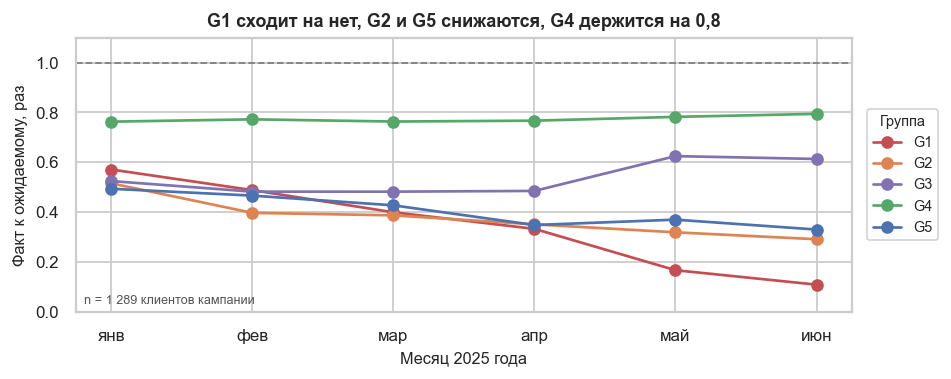

In [8]:
fig, ax = plt.subplots(figsize=(7.2, 2.8), layout="constrained")
for g, col in zip(GROUPS, ["#C44E52", "#DD8452", "#8172B2", "#55A868", "#4C72B0"]):
    ax.plot(range(1, 7), prof[g], marker="o", color=col, label=g.split(" ", 1)[0])
ax.axhline(1, color="grey", ls="--", lw=1)
ax.set_xticks(range(1, 7)); ax.set_xticklabels(["янв", "фев", "мар", "апр", "май", "июн"])
ax.set_ylim(0, 1.1); ax.set_xlabel("Месяц 2025 года"); ax.set_ylabel("Факт к ожидаемому, раз")
ax.set_title("G1 сходит на нет, G2 и G5 снижаются, G4 держится на 0,8")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), title="Группа")
ax.text(0.01, 0.03, f"n = {K['n_campaign']:,} клиентов кампании".replace(",", " "), transform=ax.transAxes, fontsize=7, color="#555")
plt.show()

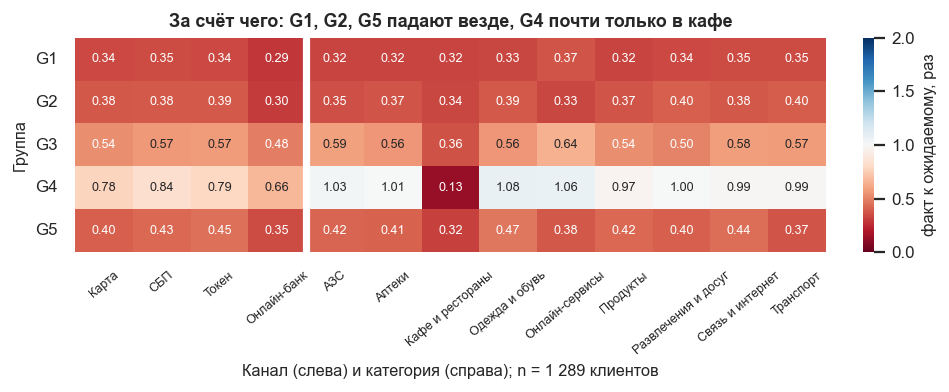

In [9]:
fig, ax = plt.subplots(figsize=(7.2, 2.9), layout="constrained")
heat = pd.concat([idx_ch[["Карта", "СБП", "Токен", "Онлайн-банк"]], idx_cat], axis=1)
heat.index = [g.split(" ", 1)[0] for g in heat.index]
sns.heatmap(heat, annot=True, fmt=".2f", cmap="RdBu", center=1, vmin=0, vmax=2, ax=ax, annot_kws={"size": 7},
            cbar_kws={"label": "факт к ожидаемому, раз"})
ax.axvline(4, color="white", lw=4)
ax.set_xlabel(f"Канал (слева) и категория (справа); n = {K['n_campaign']:,} клиентов".replace(",", " ")); ax.set_ylabel("Группа")
ax.tick_params(axis="y", rotation=0)
ax.set_title("За счёт чего: G1, G2, G5 падают везде, G4 почти только в кафе")
ax.tick_params(axis="x", rotation=40, labelsize=7)
plt.show()

## 6. Кого не включаем и почему

Баланс по всем 6 000 клиентам из двух выгрузок (справочник и операции).

In [10]:
n_orph = int(re.search(r"\d+", L("client_id", "нет в справочнике")["scope"]).group())
n_conf = int(re.search(r"\d+", L("client_id", "неоднозначными")["scope"]).group())
rule_any = metrics.rule_group.fillna("") != ""
consent = metrics.consent.astype(bool)
rest = metrics[metrics.measurable & ~rule_any]
n_all = len(metrics) + n_conf + n_orph
excl = pd.DataFrame([
    ("Нет в справочнике действующих клиентов (только в операциях)", n_orph, "нет сегмента, возраста и согласия; операции исчезают к апрелю 2025"),
    ("Конфликт атрибутов в справочнике (две версии города или сегмента)", n_conf, "правило группы применить нельзя"),
    ("Нет операций в 2024 (в основном карта открыта в 2025)", int((metrics.base12 == 0).sum()), "падение измерить нельзя"),
    ("Меньше 2 операций в месяц в 2024", int(((metrics.base12 > 0) & ~metrics.measurable).sum()), "падение не отличить от шума"),
    ("Подходят под правило группы, но нет согласия на коммуникацию", int((rule_any & ~consent).sum()), "связываться нельзя"),
    ("Активность не снизилась (индекс 0,9 и выше)", int((rest.ai >= 0.9).sum()), "кампания по возврату не нужна"),
    ("Умеренное снижение (индекс 0,6-0,9)", int(((rest.ai < 0.9) & (rest.ai > 0.6)).sum()), "в пределах обычных колебаний"),
    ("Падение, но не подошло ни под одно правило группы", int((rest.ai <= 0.6).sum()), "нет понятной группы и причины"),
    ("Включены в кампанию", len(campaign), "5 групп"),
], columns=["Кого не включаем", "Клиентов", "Почему"])
excl["Доля, %"] = (excl["Клиентов"] / n_all * 100).round(1).astype(str).str.replace(".", ",", regex=False)
K["n_all"], K["n_orph"], K["n_conf"] = n_all, n_orph, n_conf
K["swap_share"] = K["swap"] / int(metrics.measurable.sum())
K["ex"] = excl["Клиентов"].tolist()
assert excl["Клиентов"].sum() == n_all
display(excl.style.hide(axis="index"))

Кого не включаем,Клиентов,Почему,"Доля, %"
Нет в справочнике действующих клиентов (только в операциях),361,"нет сегмента, возраста и согласия; операции исчезают к апрелю 2025","6,0"
Конфликт атрибутов в справочнике (две версии города или сегмента),14,правило группы применить нельзя,"0,2"
Нет операций в 2024 (в основном карта открыта в 2025),407,падение измерить нельзя,"6,8"
Меньше 2 операций в месяц в 2024,509,падение не отличить от шума,"8,5"
"Подходят под правило группы, но нет согласия на коммуникацию",181,связываться нельзя,"3,0"
"Активность не снизилась (индекс 0,9 и выше)",2110,кампания по возврату не нужна,"35,2"
"Умеренное снижение (индекс 0,6-0,9)",971,в пределах обычных колебаний,"16,2"
"Падение, но не подошло ни под одно правило группы",158,нет понятной группы и причины,"2,6"
Включены в кампанию,1289,5 групп,"21,5"


Отдельно: у 355 клиентов (7,5% измеримых) карта упала, токен вырос, а общая активность не снизилась. Это не снижение активности, и в кампанию они не идут (они вошли в строку «Активность не снизилась»).

## 7. Что проверили и что не подтвердилось

In [12]:
ci = metrics.merge(clients[["client_id", "app_last_login", "satisfaction_score"]], on="client_id")
hyp = []
r_city = h1e.groupby("city").size() / h1b.groupby("city").size()
mass = ci[(ci.segment == "Массовый") & ci.measurable]
ai_city = mass.groupby("city").ai.median()
nn_mass = (clients[clients.city == "Нижний Новгород"].segment == "Массовый").mean()
hyp.append(("Нижний Новгород падает сильнее других городов",
            f"{r_city['Нижний Новгород']:.2f} против {r_city.drop('Нижний Новгород').min():.2f}-{r_city.drop('Нижний Новгород').max():.2f}; массовых там {nn_mass:.0%}. Внутри массового сегмента: {ai_city['Нижний Новгород']:.2f} против {ai_city.drop('Нижний Новгород').min():.2f}-{ai_city.drop('Нижний Новгород').max():.2f}",
            "Не подтвердилось: эффект состава клиентов, не города"))
lag = (pd.Period("2025-06", "M").ordinal - ci.app_last_login.dropna().dt.to_period("M").map(lambda p: p.ordinal))
ml = ci.loc[lag.index].assign(lag=lag)
ml = ml[ml.measurable & (ml.segment == "Массовый")]
lb = pd.cut(ml.lag, [-1, 3, 12, 100], labels=["до 3 мес.", "3-12 мес.", "больше года"])
r_lag = ml.groupby(lb, observed=True).ai.median()
hyp.append(("Кто давно не заходил в приложение, падает сильнее (массовые с приложением)",
            "индекс активности (медиана): " + ", ".join(f"{k} {v:.2f}" for k, v in r_lag.items()) + f"; n = {len(ml):,}".replace(",", " "),
            "Не подтвердилось: связи нет"))
sat = ci[ci.measurable & (ci.segment == "Массовый") & ci.satisfaction_score.notna()]
r_sat = sat.groupby("satisfaction_score").ai.median()
hyp.append(("Недовольные клиенты падают сильнее (массовый сегмент)",
            "индекс (медиана) по оценкам 1-5: " + ", ".join(f"{v:.2f}" for v in r_sat.values) + f"; n = {len(sat):,}".replace(",", " "),
            "Слабо: у оценки 1 ниже, но их мало, оценка есть не у всех"))
st = ci[ci.measurable & (ci.segment == "Зарплатный")]
hyp = [(h, ru(c_), v) for h, c_, v in hyp]
tab_hyp = pd.DataFrame(hyp, columns=["Гипотеза", "Проверка (число)", "Вывод"])
K["hyp"] = hyp
display(tab_hyp.style.hide(axis="index"))

Гипотеза,Проверка (число),Вывод
Нижний Новгород падает сильнее других городов,"0,78 против 0,91-0,94; массовых там 87%. Внутри массового сегмента: 0,70 против 0,70-0,75","Не подтвердилось: эффект состава клиентов, не города"
"Кто давно не заходил в приложение, падает сильнее (массовые с приложением)","индекс активности (медиана): до 3 мес. 0,83, 3-12 мес. 0,83, больше года 0,84; n = 1 455",Не подтвердилось: связи нет
Недовольные клиенты падают сильнее (массовый сегмент),"индекс (медиана) по оценкам 1-5: 0,63, 0,75, 0,70, 0,78, 0,78; n = 828","Слабо: у оценки 1 ниже, но их мало, оценка есть не у всех"


## 8. Приложение

### А. Сводка журнала изменений

In [13]:
display(log)

,field,issue,scope,n_rows,value_before,action,value_after,rationale
0,"registration_date, card_open_date",дата хранится текстом «ДД.ММ.ГГГГ»,все строки clients,5694,19.12.2016 (str),преобразовано,2016-12-19 (datetime64),Формат ДД.ММ.ГГГГ определён по данным: первая ...
1,birth_date,дата хранится текстом «ГГГГ-ММ-ДД»,все строки clients,5694,1975-07-19 (str),преобразовано,1975-07-19 (datetime64),"ISO-формат: все значения подошли под маску, по..."
2,app_last_login,месяц хранится текстом «ГГГГ-ММ»,строки с известным месяцем входа,3496,2025-01 (str),преобразовано,2025-01-01 (datetime64),"значение означает месяц, день; пустые не тронуты"
3,txn_datetime,два формата записи: с временем и только дата,все строки transactions,623808,2024-01-06 18:01:28 / 2024-01-06,"преобразовано, добавлен флаг has_time",datetime64; для строк без времени 00:00:00,"У 50,082 строк времени в источнике нет; время ..."
4,amount,сумма хранится текстом с десятичной запятой,все строки transactions,623808,"547,62 (str)",преобразовано,547.62 (float64),Преобразован формат в корректный для поля хран...
5,"monthly_income, satisfaction_score",числа хранятся текстом,строки с непустым значением,5113,34400.0 (str),преобразовано,34400.0 (float64),пустые остались NaN; Преобразован формат в кор...
6,age,"возраст в данных отсутствует, есть только дата...",все строки clients,5694,нет столбца,добавлен,"age = (30.06.2025 - birth_date) / 365.25, лет",нужен для правил групп; опорная дата 30.06.202...
7,city,17 написаний вместо 6 городов,строки с неканоническим написанием,1671,"г. Москва, ' москва', МОСКВА, СПб, Н. Новгород",нормализовано,"6 городов: Екатеринбург, Казань, Москва, Нижни...",для корректной работы необходимо соответсвие с...
8,category,12 написаний вместо 9 категорий,операции с неканоническим написанием,53855,"Кафе/рестораны, кафе и рестораны, Связь и Инте...",нормализовано,9 категорий,для корректной работы необходимо соответсвие с...
9,mcc_code / category,MCC не соответствует категории,операции с несовпадением,1624,категория Продукты при MCC другой категории,"оставлено, добавлен флаг mcc_mismatch","category без изменений, mcc_mismatch=True","расхождение случайное и редкое (0.26%), распре..."


### Б. Методика: формулы, фильтры, пороги

*Ожидаемое*<sub>i</sub> = (операций клиента i в 2024 / 12) × Σ s<sub>m</sub>, m = 1…6; *индекс активности* AI<sub>i</sub> = факт<sub>i</sub> (январь-июнь 2025) / ожидаемое<sub>i</sub>; s<sub>m</sub> = операции банка в месяце m 2024 / среднемесячные операции банка 2024. Индекс мая-июня считается так же по двум месяцам. Фильтры: успешные операции, период 2024-01-01 - 2025-06-30, клиенты из справочника без конфликта атрибутов. Выбросы в суммах искали по межквартильному размаху на логарифмической шкале внутри категории (1,5 МКР; квартили методом линейной интерполяции), доход ниже разрыва в 50 раз исправлен умножением на 1000. Все доли указаны вместе со знаменателем в подписях и таблицах.

In [13]:
thr = pd.DataFrame([
    ("Измеримая база", "не менее 2 успешных операций в месяц в 2024", "меньше - падение не отличить от шума"),
    ("Индекс активности AI", "факт янв.-июнь 2025 / ((операций клиента в 2024 / 12) × Σ s_m, m = 1..6)", "s_m = операции банка в месяце m 2024 / среднемесячные операции банка 2024"),
    ("G1 угасание", "массовый, нет приложения, индекс мая-июня ≤ 0,35", "в мае-июне осталось не более 35% ожидаемого"),
    ("G2 глубокое снижение", "массовый, есть приложение, AI ≤ 0,6", "падение на 40% и больше"),
    ("G3 умеренное снижение", "массовый, нет приложения, индекс мая-июня > 0,35 и AI ≤ 0,75", "падение до 25%, но не до нуля"),
    ("G4 кафе и рестораны", "премиальный или Private; ожидаемых операций в кафе ≥ 6; факт ≤ 50% ожидаемого; остальные ≥ 80%", "падение за счёт одной категории"),
    ("G5 старшие", "не массовый, возраст ≥ 55, AI ≤ 0,6, не подошёл под G4", "общее снижение у старших"),
    ("Приоритет при пересечении", "G1 > G2 > G3 > G4 > G5", "пересекаются только G4 и G5 (более конкретная причина важнее общей)"),
    ("Согласие", "marketing_opt_in = Да", "без согласия связываться нельзя"),
], columns=["Параметр", "Правило или значение", "Пояснение"])
display(thr.style.hide(axis="index"))
sm = pd.DataFrame({"месяц": ["янв", "фев", "мар", "апр", "май", "июн", "июл", "авг", "сен", "окт", "ноя", "дек"],
                   "s_m": season.round(3).astype(str).str.replace(".", ",", regex=False).values}).set_index("месяц").T
K["season"] = season
display(sm.style)

Параметр,Правило или значение,Пояснение
Измеримая база,не менее 2 успешных операций в месяц в 2024,меньше - падение не отличить от шума
Индекс активности AI,"факт янв.-июнь 2025 / ((операций клиента в 2024 / 12) × Σ s_m, m = 1..6)",s_m = операции банка в месяце m 2024 / среднемесячные операции банка 2024
G1 угасание,"массовый, нет приложения, индекс мая-июня ≤ 0,35",в мае-июне осталось не более 35% ожидаемого
G2 глубокое снижение,"массовый, есть приложение, AI ≤ 0,6",падение на 40% и больше
G3 умеренное снижение,"массовый, нет приложения, индекс мая-июня > 0,35 и AI ≤ 0,75","падение до 25%, но не до нуля"
G4 кафе и рестораны,премиальный или Private; ожидаемых операций в кафе ≥ 6; факт ≤ 50% ожидаемого; остальные ≥ 80%,падение за счёт одной категории
G5 старшие,"не массовый, возраст ≥ 55, AI ≤ 0,6, не подошёл под G4",общее снижение у старших
Приоритет при пересечении,G1 > G2 > G3 > G4 > G5,пересекаются только G4 и G5 (более конкретная причина важнее общей)
Согласие,marketing_opt_in = Да,без согласия связываться нельзя


месяц,янв,фев,мар,апр,май,июн,июл,авг,сен,окт,ноя,дек
s_m,"0,717","0,893","1,023","0,998","0,913","0,988","1,02","1,063","1,015","1,047","1,037","1,286"


### Г. Использование ИИ

- **Для чего:** ИИ-ассистент (Claude) помогал в сложных блоках кода, построении таблиц и оформить отчёт.